## 11. Experiment 1 — Dataset inspection

In [17]:
import sys
sys.path.append("/kaggle/input/datasets/tngdngnguynl/lab04-preprocessing")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from gensim.models import Word2Vec
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
from preprocessing import split_data, tokenize, average_vectors

path = "/kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv"
df = pd.read_csv(path)
df["length"] = df["review"].str.split().str.len()

class_distribution = df["sentiment"].value_counts().rename_axis("Class").reset_index(name="Count")
class_distribution["Percentage"] = class_distribution["Count"] / len(df) * 100

print("Samples:", len(df))
print("Classes:", df["sentiment"].nunique())
display(class_distribution)
print(df["length"].describe())
print("Duplicates:", df["review"].duplicated().sum())
print("Missing text:", df["review"].isna().sum())
print("Missing labels:", df["sentiment"].isna().sum())

Samples: 50000
Classes: 2


,Class,Count,Percentage
0,positive,25000,50.0
1,negative,25000,50.0


count    50000.000000
mean       231.156940
std        171.343997
min          4.000000
25%        126.000000
50%        173.000000
75%        280.000000
max       2470.000000
Name: length, dtype: float64
Duplicates: 418
Missing text: 0
Missing labels: 0


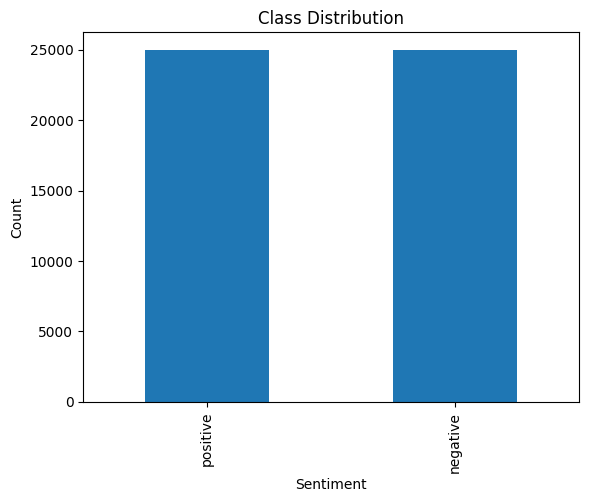

In [18]:
df["sentiment"].value_counts().plot(kind="bar")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.title("Class Distribution")
plt.show()

### Nhận xét
Dataset không bị imbalance vì positive và negative đều có 25,000 mẫu, mỗi lớp chiếm 50%.


## 12. Data leakage

Nếu fit TF-IDF trước khi chia dữ liệu, TF-IDF đã nhìn thấy từ và tần suất từ ở validation/test. Khi đó kết quả đánh giá không còn khách quan. Vì vậy chỉ fit TF-IDF trên tập train.


## 13. Core implementation

In [19]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(df)
print("Train:", len(X_train), "Validation:", len(X_val), "Test:", len(X_test))

model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(max_iter=1000))
])

Train: 40000 Validation: 5000 Test: 5000


## 14. Experiment 2 — Baseline

In [20]:
start = time.time()
model.fit(X_train, y_train)
training_time = time.time() - start

y_pred = model.predict(X_val)
vocab_size = len(model.named_steps["tfidf"].vocabulary_)

baseline_result = {
    "Representation": "TF-IDF",
    "Classifier": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_pred),
    "Precision": precision_score(y_val, y_pred),
    "Recall": recall_score(y_val, y_pred),
    "F1": f1_score(y_val, y_pred)
}

print("Training time:", training_time)
print("Vocabulary size:", vocab_size)
print(pd.Series(baseline_result))

Training time: 11.625940322875977
Vocabulary size: 92647
Representation                 TF-IDF
Classifier        Logistic Regression
Accuracy                       0.9032
Precision                    0.895294
Recall                         0.9132
F1                           0.904158
dtype: object


## 15. Experiment 3 — Representation comparison

### Model B — Average Word2Vec + Logistic Regression

In [21]:
train_tokens = tokenize(X_train)
val_tokens = tokenize(X_val)

w2v = Word2Vec(train_tokens, vector_size=100, window=5, min_count=2)
X_train_w2v = average_vectors(train_tokens, w2v)
X_val_w2v = average_vectors(val_tokens, w2v)

w2v_model = LogisticRegression(max_iter=1000)
w2v_model.fit(X_train_w2v, y_train)
y_pred_w2v = w2v_model.predict(X_val_w2v)

w2v_result = {
    "Representation": "Avg Word2Vec",
    "Classifier": "Logistic Regression",
    "Accuracy": accuracy_score(y_val, y_pred_w2v),
    "Precision": precision_score(y_val, y_pred_w2v),
    "Recall": recall_score(y_val, y_pred_w2v),
    "F1": f1_score(y_val, y_pred_w2v)
}

print(pd.Series(w2v_result))

Representation           Avg Word2Vec
Classifier        Logistic Regression
Accuracy                       0.8272
Precision                      0.8151
Recall                         0.8464
F1                           0.830455
dtype: object


### Model C — TF-IDF + Linear SVM

In [22]:
svm_model = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LinearSVC())
])

svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_val)

svm_result = {
    "Representation": "TF-IDF",
    "Classifier": "Linear SVM",
    "Accuracy": accuracy_score(y_val, y_pred_svm),
    "Precision": precision_score(y_val, y_pred_svm),
    "Recall": recall_score(y_val, y_pred_svm),
    "F1": f1_score(y_val, y_pred_svm)
}

print(pd.Series(svm_result))

Representation        TF-IDF
Classifier        Linear SVM
Accuracy              0.9034
Precision           0.894716
Recall                0.9144
F1                  0.904451
dtype: object


In [23]:
results = pd.DataFrame([baseline_result, w2v_result, svm_result])
display(results)
results.to_csv("results.csv", index=False)

,Representation,Classifier,Accuracy,Precision,Recall,F1
0,TF-IDF,Logistic Regression,0.9032,0.895294,0.9132,0.904158
1,Avg Word2Vec,Logistic Regression,0.8272,0.815100,0.8464,0.830455
2,TF-IDF,Linear SVM,0.9034,0.894716,0.9144,0.904451


## 16. Representation comparison — Nhận xét

TF-IDF cho kết quả tốt hơn Average Word2Vec trên IMDb (F1 0.9042 so với 0.8219). TF-IDF giữ được các từ quan trọng cho cảm xúc, còn Average Word2Vec lấy trung bình nên có thể làm mất thứ tự từ và giảm ảnh hưởng của các từ quan trọng.


## 17. Word order

Average Word2Vec không hiểu rõ vai trò của `not` trong `not good`. Khi lấy trung bình, `not` chỉ được cộng như một từ khác nên quan hệ phủ định giữa hai từ không được giữ lại.


## 18. Experiment 5 — n-gram features

In [24]:
bigram_model = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2))),
    ("classifier", LogisticRegression(max_iter=1000))
])

start = time.time()
bigram_model.fit(X_train, y_train)
bigram_time = time.time() - start
y_pred_bigram = bigram_model.predict(X_val)

ngram_results = pd.DataFrame([
    ["Unigram", vocab_size, f1_score(y_val, y_pred), training_time],
    ["Uni + Bigram", len(bigram_model.named_steps["tfidf"].vocabulary_), f1_score(y_val, y_pred_bigram), bigram_time]
], columns=["Features", "Vocabulary", "F1", "Training time"])

display(ngram_results)

,Features,Vocabulary,F1,Training time
0,Unigram,92647,0.904158,11.625940
1,Uni + Bigram,2110390,0.902909,62.569832


### Nhận xét

Bigram có thể giữ các cụm như `not good`, nhưng làm số lượng feature tăng rất mạnh. Trong kết quả này, vocabulary tăng từ 92,647 lên 2,110,390 và thời gian train tăng từ 10.93s lên 60.81s, trong khi F1 giảm nhẹ từ 0.9042 xuống 0.9029.


## 20. Confusion matrix

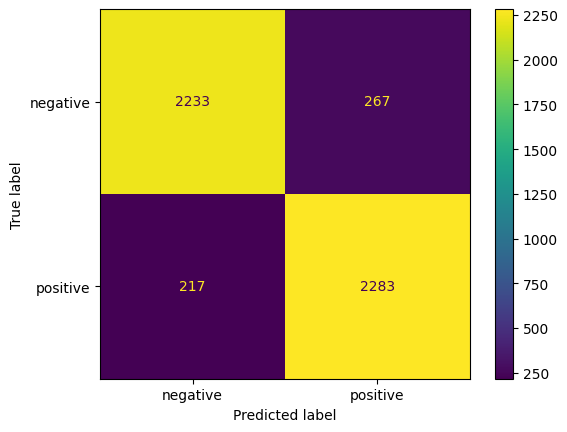

In [25]:
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred, display_labels=["negative", "positive"]
)
plt.savefig("confusion_matrix.png", bbox_inches="tight")
plt.show()

### Nhận xét

Negative bị nhầm sang positive nhiều hơn: 267 mẫu, so với 217 mẫu positive bị nhầm sang negative. Vì false positive nhiều hơn false negative nên Precision phản ánh rõ vấn đề này; Precision cũng thấp hơn Recall.


## 21. Error analysis

In [26]:
labels = {0: "negative", 1: "positive"}
error_df = pd.DataFrame({
    "Text": X_val.values,
    "True": [labels[x] for x in y_val.values],
    "Predicted": [labels[x] for x in y_pred]
})

correct_samples = error_df[error_df["True"] == error_df["Predicted"]].sample(3, random_state=42)
incorrect_samples = error_df[error_df["True"] != error_df["Predicted"]].sample(3, random_state=42)

display(correct_samples)
display(incorrect_samples)

,Text,True,Predicted
1728,"I, for one, absolutely loved this movie.<br />...",positive,positive
1568,This movie is just another average action flic...,negative,negative
4436,This movie scared heck out of me when I was ju...,positive,positive


,Text,True,Predicted
4263,"""House of Dracula"" isn't all that bad of a fil...",positive,negative
4930,The NYT review says that Sigourney Weaver's ch...,positive,negative
1887,I missed the beginning but I did see most of i...,negative,positive


## 22. Inspect model weights

In [27]:
tfidf = model.named_steps["tfidf"]
clf = model.named_steps["classifier"]
features = np.array(tfidf.get_feature_names_out())
weights = clf.coef_[0]

positive_idx = np.argsort(weights)[-10:][::-1]
negative_idx = np.argsort(weights)[:10]

top_positive = pd.DataFrame({"Feature": features[positive_idx], "Weight": weights[positive_idx]})
top_negative = pd.DataFrame({"Feature": features[negative_idx], "Weight": weights[negative_idx]})

display(top_positive)
display(top_negative)

,Feature,Weight
0,great,8.806805
1,excellent,7.430747
2,best,5.634857
3,perfect,5.611981
4,wonderful,5.141145
5,amazing,5.126353
6,loved,4.814875
7,enjoyed,4.594796
8,fun,4.424613
9,brilliant,4.332755


,Feature,Weight
0,worst,-11.054083
1,bad,-9.307337
2,awful,-8.259308
3,waste,-8.010474
4,boring,-7.201748
5,poor,-6.434099
6,terrible,-6.364630
7,nothing,-5.665740
8,worse,-5.346936
9,dull,-5.273588


### Nhận xét

Các feature nhìn chung hợp lý với bài toán sentiment. Những từ như `great`, `excellent`, `amazing` nghiêng về positive, còn `worst`, `bad`, `awful`, `boring` nghiêng về negative.
